In [8]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pickle
from functools import lru_cache
from itertools import product

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib import cm
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sys.path.insert(0, os.path.abspath(".."))  # WM Model/
from Generators.AnalGen import Analytical_Search, grid_gen, state_diagram

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# $J_{crit}$ Study 

In [9]:
def phi_E(I, a_E, b_E, d_E):
    a_expanded = np.tile(a_E, 2)[:, None]   # shape (60, 1)
    return (a_expanded * I - b_E) / (1 - np.exp(np.clip(-d_E * (a_expanded * I - b_E), -700, 700)))

def phi_I(I, g_I, c_1, c_0, r0_I):
    return np.maximum((1 / g_I) * (c_1 * I - c_0) + r0_I, 0)


def bifucation_plot(age='Y', aging_mechanism={'spine','FI'}, area='9/46d', tolerance=1e-4, Js_min=0.3, Js_max=0.8):
    Js_list = np.round(np.linspace(Js_min, Js_max, 201), 4)
    # Y range: given vals
    # MA range: 
    #       FI : given vals
    #       spine   2 - 3.5
    #       combination: 1.5 - 2
    # A range: 
    #       FI :   given vals
    #       spine   8 - 9
    #       combination:  4 - 5
    fig, ax = plt.subplots()
    Setup = Analytical_Search(age=age, aging_mechanism=aging_mechanism)

    def has_mem(res):
        _, rates, eigs = res
        return any(np.all(e.real < 0) and abs(r[0] - r[1]) > 5 for r, e in zip(rates, eigs))

    def has_hall(res):
        _, rates, eigs = res
        return any(np.any(e.real > 0) and abs(r[0] - r[1]) < 1e-10 for r, e in zip(rates, eigs))
    
    # One scan, reused for both J_crit and the plot
    scan = [Setup.fixedpoint_computation(Js, area=area) for Js in Js_list]
    flags_crit = np.array([has_mem(res) for res in scan])
    flags_hall = np.array([has_hall(res) for res in scan])

    # J_crit: bisect only inside the first grid cell where the flag turns True
    if flags_crit[0] or not flags_crit.any():
        J_crit = np.nan
    else:
        k = flags_crit.argmax()
        lo, hi = Js_list[k - 1], Js_list[k]
        while hi - lo > tolerance:
            mid = (lo + hi) / 2
            lo, hi = (lo, mid) if has_mem(Setup.fixedpoint_computation(mid, area=area)) else (mid, hi)
        J_crit = round(hi, 4)

    # J_hall: bisect only inside the first grid cell where the flag turns True
    if flags_hall[0] or not flags_hall.any():
        J_hall = np.nan
    else:
        k = flags_hall.argmax()
        lo, hi = Js_list[k - 1], Js_list[k]
        while hi - lo > tolerance:
            mid = (lo + hi) / 2
            lo, hi = (lo, mid) if has_hall(Setup.fixedpoint_computation(mid, area=area)) else (mid, hi)
        J_hall = round(hi, 4)

    # Plot from the stored scan (no recomputation)
    for Js, (S, R, E) in zip(Js_list, scan):
        for rates, eig in zip(R, E):
            ax.scatter(Js, rates[0] - rates[1], color='green' if np.all(eig.real < 0) else 'red', alpha=0.5, s=1)

    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.axvline(J_crit, color='k', linestyle='--', linewidth=0.8)
    ax.axvline(J_hall, color='k', linestyle='-.', linewidth=0.8)
    ax.set_xlabel("$J_s$")

    full_ages = {'Y': 'Young', 'MA': 'Middle Aged', 'A': 'Aged'}
    full_mech = {
        'spine': 'Spine Count Aging Mechanism',
        'FI': 'Neuronal Hyperexcitability Aging Mechanism',
        frozenset({'spine','FI'}): 'Both Aging Mechanisms',
        frozenset({'spine','FI','longrange'}): 'Three Aging Mechanisms'
    }
    mech = aging_mechanism
    if type(aging_mechanism) == set:
        mech = frozenset(aging_mechanism)

    plt.suptitle(f'Bifurcation diagram for {full_ages[age]} Network\n with {full_mech[mech]}')
    ax.set_ylabel("$r^*_{E1}- r^*_{E2}$")
    legend_elements = [
        Line2D([0], [0], color='green', linestyle=':', markersize=8, label='Stable fixed point'),
        Line2D([0], [0], color='red', linestyle=':', markersize=8, label='Saddle'),
        Line2D([0], [0], color='k', linestyle=':', markersize=8, label=rf'$J_{{crit}}$={J_crit}'),
        Line2D([0], [0], color='k', linestyle='-.', markersize=8, label=rf'$J_{{hall}}$={J_hall}')
    ]
    ax.legend(handles=legend_elements, loc='upper left', fontsize=9)
    plt.savefig(f'Fig/bifucation_{aging_mechanism}_{age}.svg', dpi=150, bbox_inches='tight')
    plt.show()

def bifurcation_critvals(age='Y', aging_mechanism={'spine', 'FI'}, tol=1e-3, Js_min=0.21, Js_start=0.8, Js_cap=100.0):
    model = Analytical_Search(age=age, aging_mechanism=aging_mechanism)

    @lru_cache(maxsize=None)
    def fxps(Js, area):
        _, rates, eigs = model.fixedpoint_computation(Js, area=area)
        return tuple((abs(r[0] - r[1]), bool(np.all(e.real < 0))) for r, e in zip(rates, eigs))

    Jcrit   = lambda Js, area: any(stable and diff > 5 for diff, stable in fxps(Js, area))
    Juncrit = lambda Js, area: not any(stable and diff < 1e-3 for diff, stable in fxps(Js, area))

    def find_critical_Js(condition, area):
        if condition(Js_min, area):
            return np.nan
        lo, hi = Js_min, Js_start
        while not condition(hi, area):          # expand bracket
            lo, hi = hi, hi * 1.5
            if hi > Js_cap:
                return np.nan
        while (hi - lo) > tol * hi:             # relative bisection
            mid = (lo + hi) / 2
            lo, hi = (lo, mid) if condition(mid, area) else (mid, hi)
        return hi

    def to_effective(Js, area):                 # nominal -> effective J (same formula as the model)
        if np.isnan(Js) or 'spine' not in model.aging_mechanism:
            return Js
        D = model.D[model.idx(area)].item()
        return model.g_E_self_min + (Js - model.g_E_self_min) * D

    out = {'crit': [], 'hall': []}
    for area in model.area_list:
        out['crit'].append(to_effective(find_critical_Js(Jcrit, area), area))
        out['hall'].append(to_effective(find_critical_Js(Juncrit, area), area))
    return out

def plot_critical_points_violin(critical_points_per_age, aging_mechanism, same_plot=True):
    age_names = {'Y': 'Young', 'MA': 'Middle Aged', 'A': 'Aged'}
    age_colors = {'Y': 'tab:blue', 'MA': 'tab:orange', 'A': 'tab:green'}
    plot_settings = [('crit', r'$J_{crit}$: active memory states appear'),
                     ('hall', r'$J_{hall}$: baseline becomes unstable')]
    ref_Y = {}

    if same_plot:
        fig, ax = plt.subplots(figsize=(7, 5))
        axes = [ax, ax]
        x_offsets, markers = [-0.2, 0.2], ['o', 's']
        styles = [dict(alpha=0.45, lw=1.0, ls='-'),    # crit
                dict(lw=2.0, ls='--')]   # hall
    else:
        fig, axes = plt.subplots(1, 2, figsize=(11, 5))
        x_offsets, markers = [0, 0], ['o', 'o']
        styles = [dict(lw=1.0, ls='-')] * 2

    # first loop: draw violins (original header restored)
    for ax, (point_type, _), x_offset, marker, style in zip(axes, plot_settings, x_offsets, markers, styles):
        for age_position, age in enumerate(critical_points_per_age, start=1):
            critical_values = np.array(critical_points_per_age[age][point_type], float)
            critical_values = critical_values[~np.isnan(critical_values)]

            if not len(critical_values):
                continue

            violin_parts = ax.violinplot(critical_values, positions=[age_position + x_offset],
                                         widths=0.3, showmeans=True, showextrema=True)

            for violin_body in violin_parts['bodies']:
                violin_body.set_facecolor(to_rgba(age_colors[age]))
                violin_body.set_edgecolor(age_colors[age])
                violin_body.set_alpha(0.5)
                violin_body.set_linewidth(style['lw'])
                violin_body.set_linestyle(style['ls'])

            for line_name in ['cbars', 'cmins', 'cmaxes', 'cmeans']:
                violin_parts[line_name].set_color(age_colors[age])

            ax.scatter(np.full(len(critical_values), age_position + x_offset), critical_values,
                       color=age_colors[age], edgecolor='k', marker=marker, s=18, zorder=3)

            if age == 'Y':
                ref_Y[point_type] = np.round(np.mean(critical_values), 4)


    # second loop: Young reference lines, no legend entry
    for ax, symbol, line_style in zip(axes, ['crit', 'hall'], ['--', ':']):
        ax.set_ylabel(r'$J_s$ of isolated area (nA)' if same_plot else fr'$J_{{{symbol}}}$ of isolated area (nA)')
        if symbol in ref_Y:
            ax.axhline(ref_Y[symbol], color='k', ls=line_style, lw=0.8)

    # mark the exact Young values on the y-axis
    ax_symbols = {}
    for ax, s in zip(axes, ['crit', 'hall']):
        ax_symbols.setdefault(ax, []).append(s)

    for ax, syms in ax_symbols.items():
        vals = [float(ref_Y[s]) for s in syms if s in ref_Y]
        if not vals:
            continue
        ymin, ymax = ax.get_ylim()
        span = ymax - ymin
        # keep default ticks unless they would collide with a Young value
        ticks = [t for t in ax.get_yticks()
                 if ymin <= t <= ymax and all(abs(t - v) > 0.05 * span for v in vals)]
        pairs = sorted([(t, f'{t:g}', False) for t in ticks] +
                       [(v, f'{v:.4f}', True) for v in vals])
        ax.set_yticks([p[0] for p in pairs])
        ax.set_yticklabels([p[1] for p in pairs])
        ax.set_ylim(ymin, ymax)

    # legend only for the crit/hall marker types (same_plot case)
    if same_plot:
        type_handles = [Line2D([0], [0], color='k', linewidth=s['lw'], linestyle=s['ls'],
                               alpha=s.get('alpha', 1.0), label=title)
                        for s, (_, title) in zip(styles, plot_settings)]
        axes[0].legend(handles=type_handles)

    # x tick labels with number of valid areas
    labels = []
    for age in critical_points_per_age:
        labels.append(f"{age_names[age]}")
    for ax in set(axes):
        ax.set_xticks(range(1, len(critical_points_per_age) + 1))
        ax.set_xticklabels(labels, fontsize=8)

    full_mech = {
        'spine': 'Spine Count Aging Mechanism',
        'FI': 'Neuronal Hyperexcitability Aging Mechanism',
        frozenset({'spine', 'FI'}): 'Both Aging Mechanisms',
        frozenset({'spine', 'FI', 'longrange'}): 'Three Aging Mechanisms'
    }
    mech = frozenset(aging_mechanism) if isinstance(aging_mechanism, (set, frozenset)) else aging_mechanism

    plt.suptitle(f'{full_mech[mech]}')
    plt.tight_layout()
    name = '_'.join(sorted(aging_mechanism)) if isinstance(aging_mechanism, (set, frozenset)) else aging_mechanism
    plt.savefig(f'Fig/jcrit_violin_{name}.svg', dpi=150, bbox_inches='tight')
    plt.show()

# for aging_mech in ['FI', 'spine', {'FI','spine'}]:
#     res = {age: bifurcation_critvals(age=age, aging_mechanism = aging_mech) for age in ['Y', 'MA', 'A']}
#     plot_critical_points_violin(res, aging_mechanism = aging_mech)

def bifurcation_a_plot(a_ranges={0.26: (0, 1000), 0.468: (130, 200)}, n_a=500,
                       area='9/46d', age='Y', aging_mechanism=None, tolerance=1e-3):
    """Bifurcation of an isolated area in the gain parameter a of phi_E, at fixed J_s = Jmax.
    a_ranges maps each Jmax to its (a_min, a_max) sweep range."""
    Setup = Analytical_Search(age=age, aging_mechanism=aging_mechanism)
    i = Setup.idx(area)
    a_orig = np.array(Setup.a_E[i], copy=True)   # restored at the end

    def run(a, Js):
        Setup.a_E[i] = a
        return Setup.fixedpoint_computation(Js, area=area)

    def has_mem(res):
        _, rates, eigs = res
        return any(np.all(e.real < 0) and abs(r[0] - r[1]) > 5 for r, e in zip(rates, eigs))

    def baseline_stable(res):
        _, rates, eigs = res
        return any(np.all(e.real < 0) and abs(r[0] - r[1]) < 1e-3 for r, e in zip(rates, eigs))

    def first_switch(a_list, flags, cond, Js):
        # first grid cell where flag turns True, refined by bisection; nan if absent / already True
        if flags[0] or not flags.any():
            return np.nan
        k = flags.argmax()
        lo, hi = a_list[k - 1], a_list[k]
        while hi - lo > tolerance:
            mid = (lo + hi) / 2
            lo, hi = (lo, mid) if cond(run(mid, Js)) else (mid, hi)
        return round(hi, 4)

    fig, axes = plt.subplots(1, len(a_ranges), figsize=(6 * len(a_ranges), 4.5), squeeze=False)
    try:
        for col, (Js, (a_min, a_max)) in enumerate(a_ranges.items()):
            ax = axes[0, col]
            a_list = np.linspace(a_min, a_max, n_a)
            scan = [run(a, Js) for a in a_list]
            a_crit = first_switch(a_list, np.array([has_mem(r) for r in scan]), has_mem, Js)
            a_hall = first_switch(a_list, np.array([not baseline_stable(r) for r in scan]),
                                  lambda r: not baseline_stable(r), Js)

            for a, (S, R, E) in zip(a_list, scan):
                for rates, eig in zip(R, E):
                    color = 'green' if np.all(eig.real < 0) else 'red'
                    ax.scatter(a, rates[0] - rates[1], color=color, alpha=0.5, s=1)

            if not np.isnan(a_crit):
                ax.axvline(a_crit, color='k', linestyle='--', linewidth=0.8)
            if not np.isnan(a_hall):
                ax.axvline(a_hall, color='k', linestyle='-.', linewidth=0.8)
            ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)

            ax.set_title(rf'$J_s = {Js}$ nA')
            ax.set_ylabel(r"$r^*_{E1}- r^*_{E2}$")
            ax.set_xlabel("$a$ (Hz/nA)")
            ax.legend(handles=[
                Line2D([0], [0], color='green', marker='o', ls='', label='Stable fixed point'),
                Line2D([0], [0], color='red', marker='o', ls='', label='Saddle / unstable'),
                Line2D([0], [0], color='k', ls='--', label=rf'$a_{{crit}}$={a_crit}'),
                Line2D([0], [0], color='k', ls='-.', label=rf'$a_{{hall}}$={a_hall}'),
            ], loc='upper left', fontsize=8)
    finally:
        Setup.a_E[i] = a_orig

    plt.suptitle(f'Bifurcation in $a$ of $\\phi_E$ for an isolated area , {age} network')
    plt.tight_layout()
    plt.savefig(f'Fig/bifurcation_a_{age}.svg', dpi=150, bbox_inches='tight')
    plt.show()

def bifurcation_Js_multi_a(a_values=(130, 135, 140, 145, 147, 150, 155, 160, 165, 170), Js_min=0.21, Js_max=0.8,
                           n_Js=201, area='9/46d', age='Y', aging_mechanism=None,
                           cmap_name='viridis'):
    """J_s bifurcation of an isolated area for several gains a of phi_E, all on one axis.
    Colour encodes a through a perceptual colormap (colorbar). Stability is not distinguished."""
    Setup = Analytical_Search(age=age, aging_mechanism=aging_mechanism)
    i = Setup.idx(area)
    a_orig = np.array(Setup.a_E[i], copy=True)   # restored at the end
    Js_list = np.round(np.linspace(Js_min, Js_max, n_Js), 4)

    cmap = plt.get_cmap(cmap_name)
    norm = mcolors.Normalize(vmin=min(a_values)-5, vmax=max(a_values)+5)

    fig, ax = plt.subplots(figsize=(8, 5.5))
    try:
        for a in a_values:
            Setup.a_E[i] = a
            c = cmap(norm(a))
            xs, ys = [], []
            for Js in Js_list:
                _, R, eig = Setup.fixedpoint_computation(Js, area=area)
                for rates, e in zip(R, eig):
                    if np.all(np.real(e) < 0):          # linearly stable
                        xs.append(Js)
                        ys.append(rates[0] - rates[1])
            ax.scatter(xs, ys, color=c, alpha=0.6, s=3)
    finally:
        Setup.a_E[i] = a_orig

    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_xlabel("$J_s$ (nA)")
    ax.set_ylabel(r"$r^*_{E1}- r^*_{E2}$")
    fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label="$a$ (Hz/nA)")

    plt.suptitle(f'$J_s$ bifurcation for different $a$, isolated area {area}, {age} network')
    plt.tight_layout()
    plt.savefig(f'Fig/bifurcation_Js_multi_a_{age}.svg', dpi=150, bbox_inches='tight')
    plt.show()
    
# bifurcation_a_plot()

# r = bifurcation_Js_multi_a(cmap_name='Blues')




## Fixed Points (all areas)

In [10]:
def Plotting_fixedpoint(grid, col='Blues', metric='active', comb_plot=True, mech={'FI','spine'}):
    """metric: 'val' for fixed-point count, 'active' for avg active areas"""

    marked_pairs = [(0.468, 0.21), (0.26, 0.48), (0.23, 0.5)]
    full_ages    = {'Y': 'Young', 'MA': 'Middle Aged', 'A': 'Aged'}
    full_mech    = {
            'spine':                'Spine Count Aging Mechanism',
            'FI':                   'Neuronal Hyperexcitability Aging Mechanism',
            frozenset({'spine','FI'}) :             'Both Aging Mechanisms',
            frozenset({'spine','FI','longrange'}) :  'Three Aging Mechanisms'
            }
    if type(mech) == set:
        mech = frozenset(mech)

    if metric == 'active':
        grid['avg_active'] = grid['R'].apply(
            lambda R_list: np.mean(pcts) if len(pcts := [
                p for R in R_list
                if (p := 100*np.sum(np.abs(R[:30] - R[30:2*30]) > 5)/30) > 0
            ]) > 0 else np.nan
        )
        value_col = 'avg_active'
        metric_label = '% Active Areas'
    else:
        value_col = 'val'
        metric_label = '# Fixed points'

    vmin = -1
    vmax = 0
    if comb_plot:
        fig, axes = plt.subplots(1, 3, figsize=(22, 5), sharey=True)
        fig.suptitle(f'{full_mech[mech]}, {metric_label}', fontsize=14, x=0.5, ha='center')
        plt.tight_layout()

    with open("data/flags.pkl", "rb") as f:
        Flags = pickle.load(f)

    for i, age in enumerate(['Y', 'MA', 'A']):
        grid_a = grid[grid.age == age]
        Z      = grid_a.pivot(index='G', columns='J_max', values=value_col)
        x      = Z.columns.values
        y      = Z.index.values
        Zvals  = np.ma.masked_invalid(Z.values.astype(int) if metric != 'active' else Z.values)
        vmax = max(np.max(Zvals),vmax)
        if not comb_plot:
            fig, ax = plt.subplots(1, 1, figsize=(7, 4))
            subtitle = f"\nwith {full_mech[mech]}"
            ax.set_title(f"{full_ages[age]} WM Network{subtitle}", fontsize=13)
        else:
            ax = axes[i]
            ax.set_title(f"{full_ages[age]} WM Network", fontsize=13)

        ax.set_title(f"{full_ages[age]} WM Network", fontsize=13)
        ax.set_xlabel(r"$J_{max}$")
 
        n_colors = vmax - vmin + 1
        cmap = plt.get_cmap(col)

        if metric == 'val':
            cmap = plt.get_cmap(col, n_colors)
            bounds = np.arange(vmin+0.5, vmax + 1, 1)
            norm = mcolors.BoundaryNorm(bounds, cmap.N)
        else: 
            vmin = 0
            vmax = 100
            norm = mcolors.Normalize(vmin=0, vmax=100)
        im = ax.pcolormesh(x, y, Zvals, cmap=cmap, shading='auto', norm=norm)

        if i == 0:
            ax.set_ylabel("G")

        if i == 2 or not comb_plot:
            if metric == 'val':
                cbar = fig.colorbar(im, ax=ax, shrink=0.9, ticks=np.arange(vmin, vmax + 1))
                cbar.set_label(metric_label)
            else:
                cbar = fig.colorbar(im, ax=ax, shrink=0.9)
                cbar.set_ticks(np.linspace(vmin, vmax, 5))
                cbar.set_label(metric_label)

        Exeds = Flags[age]
        flag_rows, flag_cols = Exeds['flag_rows'] , Exeds['flag_cols']
        ax.scatter(x[flag_cols], y[flag_rows], marker='x', color='black', s=60, linewidths=1.2, zorder=5)

        for (jm, g) in marked_pairs:
            ax.plot(jm, g, marker='x', markersize=5, color='black')
            ax.annotate(f"({jm}, {g})", xy=(jm, g), xytext=(5, -5),
                        textcoords='offset points', fontsize=7, color='black')

        if age == 'Y':
            ax.axvline(x=0.4653, color='black', linestyle='--', alpha=0.75)
            ax.plot((0.22, 0.4653), (0.48, 0.3955), color='black', linestyle='--', alpha=0.75)
            ax.annotate('Distributed WM Regime', xy=(0.35, 0.49), xytext=(0.3, 0.35),
                        arrowprops=dict(arrowstyle='->'))
            ax.annotate('Localized WM Regime',   xy=(0.49, 0.25), xytext=(0.3, 0.25),
                        arrowprops=dict(arrowstyle='->'))

        if not comb_plot:
            plt.tight_layout()
            plt.savefig(f'Fig/fixedpoints_{metric}_{age}.svg', dpi=150, bbox_inches='tight')
            plt.show()


    if comb_plot:
        plt.tight_layout()
        plt.savefig(f'Fig/fixedpoints_{metric}.svg', dpi=150, bbox_inches='tight')
        plt.show()



mech = {'FI', 'spine'}

# grid = grid_gen(mech=mech)

# os.makedirs('data', exist_ok=True)
# h5_path = f'data/seeds.pkl'
# csv_path = f'data/seeds_index.csv'

# grid.to_pickle(h5_path, compression='gzip')
# grid.drop(columns=['R']).to_csv(csv_path, index=False)
 
# print(f'Saved full grid to {h5_path}')
# print(f'Saved metadata index to {csv_path}')
# This will take 5h


In [11]:
# grid = pd.read_pickle('data/seeds.pkl', compression='gzip')

# for comb_plot in [ True, False]:
#     Plotting_fixedpoint(grid, metric='val', comb_plot=comb_plot)      
#     Plotting_fixedpoint(grid, metric='active', comb_plot=comb_plot) 

# Regime Distribution

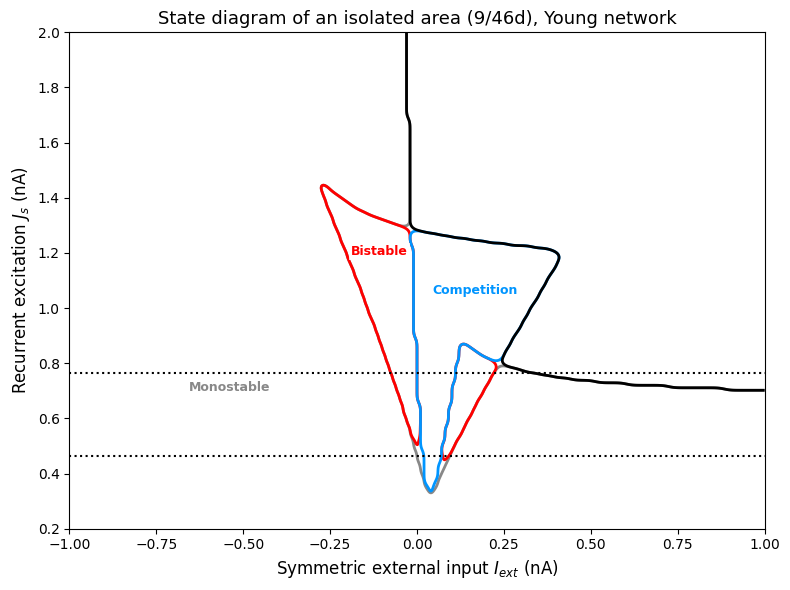

In [35]:
# from matplotlib.colors import ListedColormap, BoundaryNorm
# from matplotlib.patches import Patch
# import matplotlib.gridspec as gridspec
# from scipy.ndimage import gaussian_filter, zoom, distance_transform_edt


# age, mech, area = 'Y', {'FI', 'spine'}, '9/46d'
# n_J, n_I = 200, 200

# model = Analytical_Search(aging_mechanism=mech, age=age)
# Js_vals = np.linspace(0.2, 2, n_J)
# I_vals  = np.linspace(-1, 1, n_I)

# print(f'There are n_J x n_I = {n_J*n_I} tasks')
# def point(Js, I):
#     S, R, E = model.fixedpoint_computation(Js, area=area, I_ext=I)
#     stable = [(s, e) for s, e in zip(S, E) if np.all(e.real < 0)]
#     sym  = any(abs(s[0] - s[1]) < 1e-3 for s, _ in stable)
#     asym = any(abs(s[0] - s[1]) >= 1e-3 for s, _ in stable)
#     return {(True, False): 0, (True, True): 1, (False, True): 2}.get((sym, asym), 3)

# Z = np.array(Parallel(n_jobs=-2, verbose=5)(
#     delayed(point)(J, I) for J in Js_vals for I in I_vals)
# ).reshape(n_J, n_I)


colors = ["#888888", "#ff0000", "#0095ff", "#000000"]
labels = ['Monostable',
          'Bistable',
          'Competition',
          ' ']

up = 4                                         # upsampling factor
I_f  = np.linspace(I_vals[0], I_vals[-1], n_I * up)
Js_f = np.linspace(Js_vals[0], Js_vals[-1], n_J * up)

fig, ax = plt.subplots(figsize=(8, 6))

for k, (c, lab) in enumerate(zip(colors, labels)):
    mask = (Z == k).astype(float)
    if mask.max() == 0 or mask.min() == 1:     # regime absent, or fills everything
        continue

    # smooth: blur the binary mask, then interpolate onto a finer grid
    smooth = zoom(gaussian_filter(mask, sigma=1.5, mode='nearest'), up, order=3)
    ax.contour(I_f, Js_f, smooth, levels=[0.5], colors=[c], linewidths=2)

    # label at the most interior point of the region (robust for non-convex shapes)
    inside = smooth > 0.5
    if not inside.any():
        continue
    dist = distance_transform_edt(inside)
    jj, ii = np.unravel_index(np.argmax(dist), dist.shape)
    # label: treat the plot border as a boundary, then center among the deepest points
    inside = smooth > 0.5
    if not inside.any():
        continue
    dist = distance_transform_edt(np.pad(inside, 1, constant_values=False))[1:-1, 1:-1]
    deep = dist >= 0.9 * dist.max()
    jj, ii = np.argwhere(deep).mean(0)
    jj, ii = int(round(jj)), int(round(ii))
    if not inside[jj, ii]:                      # fallback for non-convex shapes
        jj, ii = np.unravel_index(np.argmax(dist), dist.shape)
    ax.text(I_f[ii], Js_f[jj], lab, color=c, ha='center', va='center',
            fontsize=9, fontweight='bold',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))

ax.set_xlim(I_vals[0], I_vals[-1])
ax.set_ylim(Js_vals[0], Js_vals[-1])
ax.hlines(0.4653,I_vals[0], I_vals[-1], linestyles=':', color='k')
ax.hlines(0.7649,I_vals[0], I_vals[-1], linestyles=':', color='k')
ax.set_xlabel(r'Symmetric external input $I_{ext}$ (nA)', fontsize=12)
ax.set_ylabel(r'Recurrent excitation $J_s$ (nA)', fontsize=12)
ax.set_title(f'State diagram of an isolated area ({area}), '
             f'{ {"Y":"Young","MA":"Middle Aged","A":"Aged"}[age] } network', fontsize=13)
fig.tight_layout()
fig.savefig(f'../Fig/state_diagram_{age}.svg', bbox_inches='tight')
plt.show()